C:\Users\Koen-\AppData\Local\Temp\ipykernel_27156\374066129.py:92: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()
C:\Users\Koen-\AppData\Local\Temp\ipykernel_27156\374066129.py:104: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()
C:\Users\Koen-\AppData\Local\Temp\ipykernel_27156\374066129.py:115: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


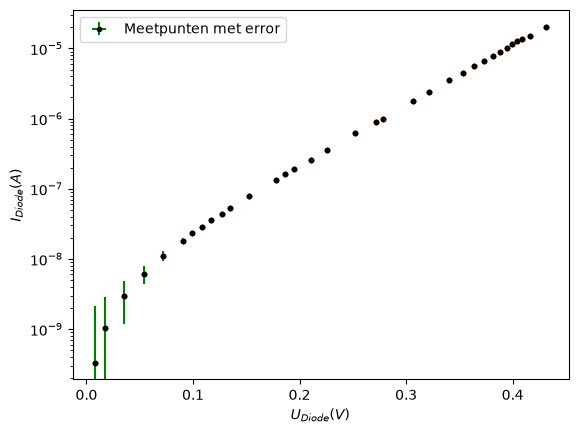

In [14]:
#import necessary libraries
import matplotlib.pyplot as plt
import numpy as np
from scipy.optimize import curve_fit 
from scipy.constants import Boltzmann as K_B

Ruw_U_R1=np.array([0.011,0.034,0.099,0.204,0.367,0.606,0.765,0.956,1.180,1.453,1.773,2.594,4.457,5.299,6.240,8.630,11.684,20.939,29.430,32.875,58.750,79.943,116.073,149.275,184.470,221.16,259.04,297.78,337.64,377.67,418.34,459.48,501.03,676.76])
Ruw_U_bron=np.array([0.09,0.19,0.39,0.59,0.79,0.99,1.09,1.19,1.29,1.4,1.49,1.69,1.99,2.09,2.19,2.39,2.59,2.98,3.285,3.39,3.98,4.38,4.98,5.48,5.98,6.48,6.98, 7.48,7.98,8.47,8.97,9.47,10.00,12.08])





#Bewerkte data
# Functies voor het berekenen van de onzekerheden
def vijfhalf(x):
    for i in range(len(U_R1)):
        if U_R1[i]<= 0.2:                                            #Er zijn 2 instellingen gebruit voor het meten van de spanning van de spanningsmeter vijfhalf.
            afstelling = 0.2 #Volt
            percentage = 0.004
        if U_R1[i]>= 0.2:                
            afstelling = 2     #Volt
            percentage = 0.003    
    return 0.015*10**-2 *x +percentage*10**-2*afstelling     
def driehalf(x):
    afstelling = 40 #Volt
    return 0.7*10**-2 * x+0.01*10**-2*afstelling               #0.7%*aflezing + 0.01%*afstelling
def vijfhalf_weerstand(x):
    afstelling = 2 # K.Ohm
    return 0.02*10**-2*x+0.003*10**-2*afstelling                   #0.02%*x+0.003%*afstelling

#Gemeten weerstanden
R1=33.149*10**3                          #33 K.Ohm 
Onzekerheid_R1=vijfhalf_weerstand(R1)+0.2 #Ohm wegens gebruik gemaakt van perform 2-wire. 
R2= 0.99466*10**3                        #1 K.Ohm
Onzekerheid_R2=vijfhalf_weerstand(R2)+0.2
R3=100.440                               #100 Ohm
Onzekerheid_R3=vijfhalf_weerstand(R3)+0.2

#Constantes
q=-1.6022e-19
Onzekerheid_q = 0                                 #Dit hebben we aangenomen
n=2
Onzekerheid_n=0.1

Temperatuur_in_celsius=19
Kelvin_bijnulgraden=273.15
T= Kelvin_bijnulgraden+ Temperatuur_in_celsius
Onzekerheid_T=2.0

#Aanpassingen van ruwe data
U_R1=Ruw_U_R1*10**-3
Verhouding = R3/(R2+R3)
U_bron = Ruw_U_bron*Verhouding



#Partieel gedoe
Onzekerheid_Ubron = driehalf(Ruw_U_bron)
Onzekerheid_U1= vijfhalf(U_R1)


#Voltage over de diode
U_D=U_bron-U_R1





#Onzekerheid klopt volgens mij
Onzekerheid_UD1 = np.sqrt((Onzekerheid_R2*(R3)/((R2+R3)**2)*U_bron)**2)
Onzekerheid_UD2=np.sqrt((Onzekerheid_R3*(R2)/((R2+R3)**2)*U_bron)**2)
Onzekerheid_UD3=np.sqrt((Onzekerheid_Ubron *(R3/(R2+R3)))**2)
Onzekerheid_UD4=np.sqrt((Onzekerheid_U1)**2)

#Stroomsterkte door de diode
I_D=U_R1/R1
Onzekerheid_ID = I_D*np.sqrt(((Onzekerheid_U1/U_R1)**2)+((Onzekerheid_R1/R1)**2))
plt.plot(U_D,I_D,'r.')
plt.yscale('log')



xerr= Onzekerheid_UD1
yerr= Onzekerheid_ID
plt.figure
plt.plot(U_D,I_D,'.')
#plt.errorbar(U_D,I_D,fmt = 'k.',xerr=xerr,yerr=yerr,ecolor = 'r',label = 'Meetpunten met error')
plt.xlabel('$U_{Diode} (V)$')
plt.ylabel('$I_{Diode} (A)$')
plt.yscale('log')          
plt.legend()



xerr= Onzekerheid_UD2
yerr= Onzekerheid_ID
plt.figure
plt.plot(U_D,I_D,'.')
#plt.errorbar(U_D,I_D,fmt = 'k.',xerr=xerr,yerr=yerr,ecolor = 'c',label = 'Meetpunten met error')
plt.xlabel('$U_{Diode} (V)$')
plt.ylabel('$I_{Diode} (A)$')
plt.yscale('log')          
plt.legend()


xerr= Onzekerheid_UD3
yerr= Onzekerheid_ID
plt.figure
plt.plot(U_D,I_D,'.')
#plt.errorbar(U_D,I_D,fmt = 'k.',xerr=xerr,yerr=yerr,ecolor = 'b',label = 'Meetpunten met error')
plt.xlabel('$U_{Diode} (V)$')
plt.ylabel('$I_{Diode} (A)$')
plt.yscale('log')          
plt.legend()


xerr= Onzekerheid_UD4
yerr= Onzekerheid_ID
plt.figure
plt.plot(U_D,I_D,'.')
plt.errorbar(U_D,I_D,fmt = 'k.',xerr=xerr,yerr=yerr,ecolor = 'g',label = 'Meetpunten met error')
plt.xlabel('$U_{Diode} (V)$')
plt.ylabel('$I_{Diode} (A)$')
plt.yscale('log')          
plt.legend()